# Face Recognition

## Part 1 — Data Preprocessing

In [ ]:
# Upload the face dataset ZIP and the supplied FaceNet code ZIP.
from google.colab import files
from zipfile import ZipFile
import os
import sys
import torch

uploaded = files.upload()
assert len(uploaded) == 2, 'Please upload both ZIP files.'
for filename in uploaded:
    with ZipFile(filename) as zip_file:
        zip_file.extractall('project_files')

# Use the Python files inside the supplied FaceNet project.
PROJECT = 'project_files/FaceNet-main'
assert os.path.isfile(PROJECT + '/data_loader.py'), 'FaceNet-main.zip is missing.'
sys.path.insert(0, PROJECT)
print('Both ZIP files extracted successfully.')

Saving Archive (1).zip to Archive (1) (3).zip
Saving FaceNet-main.zip to FaceNet-main (3).zip
Both ZIP files extracted successfully.


In [ ]:
# Read the four student folders and check that images open.
from pathlib import Path
from PIL import Image
import pandas as pd
import re

rows = []
seen = set()  # Used to detect exact duplicates.
for student in range(1, 5):
    folder = Path('project_files') / f'Tr-Subject-{student}'
    assert folder.is_dir(), f'Missing folder: {folder}'
    for path in sorted(folder.glob('*.jpg')):
        with Image.open(path) as image:
            rgb = image.convert('RGB')
            key = (rgb.size, rgb.tobytes())
            if key in seen:
                print('Duplicate skipped:', path.name)
                continue
            seen.add(key)
        # Names contain recording and frame information.
        match = re.search(r'(run\d+)_f(\d+)', path.name)
        assert match, f'Unexpected image name: {path.name}'
        rows.append([str(path), folder.name, match.group(1), int(match.group(2))])

data = pd.DataFrame(rows, columns=['path', 'subject', 'run', 'frame'])
assert len(data) == 80, 'Expected 80 unique face images.'
print('Usable images:', len(data))
print(data['subject'].value_counts().sort_index())


# Display the number of images for each student
print("Total images:", len(data))
print(data["subject"].value_counts())

# Display the number of images from each recording
print(data["run"].value_counts())

Usable images: 80
subject
Tr-Subject-1    20
Tr-Subject-2    20
Tr-Subject-3    20
Tr-Subject-4    20
Name: count, dtype: int64
Total images: 80
subject
Tr-Subject-1    20
Tr-Subject-2    20
Tr-Subject-3    20
Tr-Subject-4    20
Name: count, dtype: int64
run
run002    44
run001    36
Name: count, dtype: int64


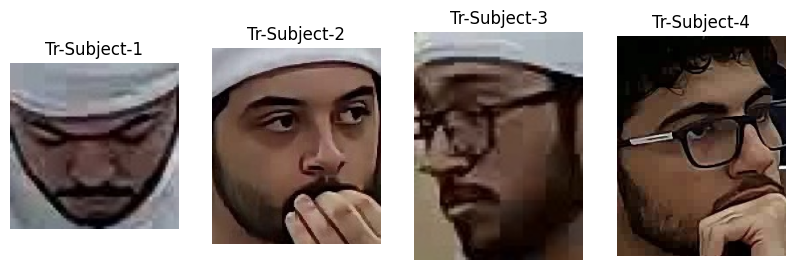

In [ ]:
# Show one example face from each student folder.
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 3))
for student in range(1, 5):
    subject = f'Tr-Subject-{student}'
    path = data[data['subject'] == subject].iloc[0]['path']
    plt.subplot(1, 4, student)
    plt.imshow(Image.open(path).convert('RGB'))
    plt.title(subject)
    plt.axis('off')
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split

# First: 70% training and 30% remaining.
train, remaining = train_test_split(
    data,
    test_size=0.30,
    random_state=42,
    stratify=data["subject"]
)

# Then divide the remaining 30%:
# 10% of all images for validation, 20% for testing.
validation, test = train_test_split(
    remaining,
    test_size=2/3,
    random_state=42,
    stratify=remaining["subject"]
)

train = train.reset_index(drop=True)
validation = validation.reset_index(drop=True)
test = test.reset_index(drop=True)

# Check the expected counts for your current 80 images.
assert (len(train), len(validation), len(test)) == (56, 8, 16)

# Check that the same image path is not in two sets.
assert set(train.path).isdisjoint(validation.path)
assert set(train.path).isdisjoint(test.path)
assert set(validation.path).isdisjoint(test.path)

splits = {
    "train": train,
    "validation": validation,
    "test": test
}

for name, frame in splits.items():
    assert set(frame.subject) == set(data.subject)
    print(
        f"{name}: {len(frame)} images "
        f"({len(frame) / len(data):.0%})"
    )

display(
    pd.DataFrame({
        name: frame.subject.value_counts()
        for name, frame in splits.items()
    }).sort_index()
)

print(
    "This is an image-level split; "
    "nearby video frames can cross sets."
)

train: 56 images (70%)
validation: 8 images (10%)
test: 16 images (20%)


,train,validation,test
subject,,,
Tr-Subject-1,14,2,4
Tr-Subject-2,14,2,4
Tr-Subject-3,14,2,4
Tr-Subject-4,14,2,4


This is an image-level split; nearby video frames can cross sets.


In [ ]:
from pathlib import Path
from uuid import uuid4
import shutil

split_root = Path("face_splits")

# Preserve any previously generated split folder.
if split_root.exists():
    backup = Path("face_splits_backup_" + uuid4().hex[:8])
    split_root.rename(backup)
    print("Previous split saved at:", backup)

# Save all three splits using the dictionary from the previous cell.
for name, frame in splits.items():
    for row in frame.itertuples():
        folder = split_root / name / row.subject
        folder.mkdir(parents=True, exist_ok=True)

        shutil.copy2(
            row.path,
            folder / Path(row.path).name
        )

    frame.to_csv(
        split_root / f"{name}.csv",
        index=False
    )

assert len(list((split_root / "train").glob("*/*.jpg"))) == 56
assert len(list((split_root / "validation").glob("*/*.jpg"))) == 8
assert len(list((split_root / "test").glob("*/*.jpg"))) == 16

print("Saved fresh training, validation and test folders.")
print("Training: 56 | Validation: 8 | Testing: 16")

Previous split saved at: face_splits_backup_71f48ec9
Saved fresh training, validation and test folders.
Training: 56 | Validation: 8 | Testing: 16


In [ ]:
# Use the preprocessing provided in FaceNet's data_loader.py.
# Training: resize + random augmentation + normalization.
# Validation/test: resize + normalization, with NO random augmentation.
from data_loader import build_transforms

from torchvision import transforms

train_transform = build_transforms(
    train=True,
    crop_size=(112, 112),
    aug_type='standard'
)
test_transform = build_transforms(train=False, crop_size=(112, 112))

example = Image.open(train.iloc[0]['path']).convert('RGB')
train_image = train_transform(example)
test_image = test_transform(example)
print('Original image size:', example.size)
print('Training tensor shape:', tuple(train_image.shape))
print('Test tensor shape:', tuple(test_image.shape))
print('Preprocessing ready')


# Preprocessing without augmentation
normal_transform = build_transforms(
    train=False,
    crop_size=(112, 112)
)

# Preprocessing with augmentation
augmented_transform = build_transforms(
    train=True,
    crop_size=(112, 112),
    aug_type="standard"
)

# Choose one training image
image_path = train.iloc[0]["path"]
image = Image.open(image_path).convert("RGB")

# Apply both transformations
normal_image = normal_transform(image)
augmented_image = augmented_transform(image)

print("Normal image shape:", normal_image.shape)
print("Augmented image shape:", augmented_image.shape)

Original image size: (195, 245)
Training tensor shape: (3, 112, 112)
Test tensor shape: (3, 112, 112)
Preprocessing ready
Normal image shape: torch.Size([3, 112, 112])
Augmented image shape: torch.Size([3, 112, 112])


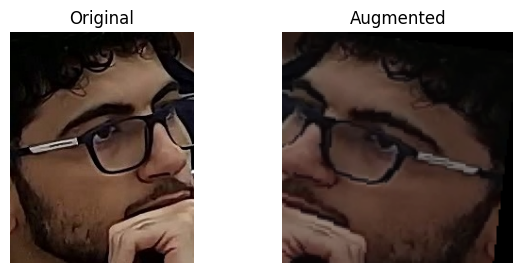

In [ ]:
# Show the original and one augmented training image.
# This undoes normalization ONLY for displaying the image.
import torch
mean = torch.tensor([0.31928781, 0.28739911, 0.25779903]).view(3, 1, 1)
std = torch.tensor([0.19799139, 0.20757903, 0.21088403]).view(3, 1, 1)
preview = (train_image * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()
plt.figure(figsize=(7, 3))
plt.subplot(1, 2, 1); plt.imshow(example); plt.title('Original'); plt.axis('off')
plt.subplot(1, 2, 2); plt.imshow(preview); plt.title('Augmented'); plt.axis('off')
plt.show()

In [ ]:
# Download the split dataset to share with the training teammate.
shutil.make_archive('face_splits', 'zip', 'face_splits')
files.download('face_splits.zip')
print('Part 1 finished')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Part 1 finished


## Part 2 — Pretrained MobileFaceNet

In [ ]:
# Load the supplied MobileFaceNet architecture and pretrained weights.
import torch
from networks.models_facenet import MobileFaceNet

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = MobileFaceNet(embedding_size=512)
weights_path = PROJECT + '/mobile_weights/model_mobilefacenet.pth'
weights = torch.load(weights_path, map_location='cpu', weights_only=True)
model.load_state_dict(weights)
model = model.to(device)
model.eval()  # Evaluation mode: no training.
print('Pretrained MobileFaceNet loaded on', device)

Pretrained MobileFaceNet loaded on cpu


In [ ]:
# Turn one training image into a 512-number embedding.
# unsqueeze(0) adds the batch dimension required by PyTorch.
image = test_transform(Image.open(train.iloc[0]['path']).convert('RGB'))
image = image.unsqueeze(0).to(device)
with torch.no_grad():
    embedding = model(image)
print('Input shape:', tuple(image.shape))
print('Embedding shape:', tuple(embedding.shape))
print('First five values:', embedding[0, :5].cpu().numpy())

Input shape: (1, 3, 112, 112)
Embedding shape: (1, 512)
First five values: [-0.05575831 -0.05552576  0.0333942  -0.09856381 -0.04263802]


In [ ]:
# Use the supplied function to create a gallery from TRAINING faces only.
from generate_embeddings import extract_embeddings

extract_embeddings(model, 'face_splits/train', device,
                   crop_size=(112, 112), batch_size=16,
                   out_path='face_gallery.npz')
print('Saved gallery: face_gallery.npz')

Found 56 images in total.


Extracting gallery embeddings: 100%|██████████| 4/4 [00:01<00:00,  3.41it/s]

Saved embeddings to face_gallery.npz (56 faces).
Saved gallery: face_gallery.npz


In [ ]:
# Evaluate Pretrained MobileFaceNet
# Test all images and calculate recognition accuracy

import torch
import numpy as np
import pandas as pd
from PIL import Image
from pathlib import Path
from data_loader import build_transforms
from generate_embeddings import search_gallery

# 1. Prepare test images without augmentation
transform = build_transforms(
    train=False,
    crop_size=(112, 112)
)

# 2. Load the gallery created in the previous cell
gallery = np.load("face_gallery.npz")
gallery_embeddings = gallery["embeddings"]
gallery_labels = gallery["labels"]

# 3. Get the names of the four students
class_names = sorted([
    folder.name
    for folder in Path("face_splits/train").iterdir()
    if folder.is_dir()
])

# 4. Set the model to evaluation mode
model.eval()

# 5. Test every image
correct = 0
results = []

for i in range(len(test)):

    # Open the test image
    image = Image.open(test.iloc[i]["path"]).convert("RGB")

    # Resize and normalize the image
    image = transform(image).unsqueeze(0).to(device)

    # Convert the image into 512 numbers
    with torch.no_grad():
        embedding = model(image).cpu().numpy()

    # Compare the embedding with the gallery
    matches = search_gallery(
        embedding,
        gallery_embeddings,
        gallery_labels
    )

    # Find the predicted student
    predicted_id = int(matches[0][0])
    predicted = class_names[predicted_id]

    # Get the actual student
    actual = test.iloc[i]["subject"]

    # Count correct predictions
    if predicted == actual:
        correct += 1

    results.append([actual, predicted])

# 6. Display all predictions
results_table = pd.DataFrame(
    results,
    columns=["Actual", "Predicted"]
)

print(results_table)

# 7. Calculate accuracy
accuracy = correct / len(test) * 100

print("Total test images:", len(test))
print("Correct predictions:", correct)
print("Baseline accuracy:", round(accuracy, 2), "%")

# 8. Save results
results_table.to_csv("baseline_predictions.csv", index=False)
print("Results saved successfully!")

          Actual     Predicted
0   Tr-Subject-1  Tr-Subject-1
1   Tr-Subject-2  Tr-Subject-2
2   Tr-Subject-2  Tr-Subject-2
3   Tr-Subject-4  Tr-Subject-4
4   Tr-Subject-4  Tr-Subject-4
5   Tr-Subject-2  Tr-Subject-2
6   Tr-Subject-2  Tr-Subject-2
7   Tr-Subject-1  Tr-Subject-1
8   Tr-Subject-1  Tr-Subject-1
9   Tr-Subject-3  Tr-Subject-3
10  Tr-Subject-4  Tr-Subject-4
11  Tr-Subject-3  Tr-Subject-3
12  Tr-Subject-1  Tr-Subject-1
13  Tr-Subject-3  Tr-Subject-3
14  Tr-Subject-3  Tr-Subject-3
15  Tr-Subject-4  Tr-Subject-4
Total test images: 16
Correct predictions: 16
Baseline accuracy: 100.0 %
Results saved successfully!


In [ ]:
# Compare one TEST face with the gallery using the supplied cosine search.
import numpy as np
from generate_embeddings import search_gallery

gallery = np.load('face_gallery.npz')
test_path = sorted(Path('face_splits/test/Tr-Subject-1').glob('*.jpg'))[0]
image = test_transform(Image.open(test_path).convert('RGB')).unsqueeze(0).to(device)
with torch.no_grad():
    query_embedding = model(image).cpu().numpy()

result = search_gallery(query_embedding, gallery['embeddings'], gallery['labels'])
class_names = sorted(p.name for p in Path('face_splits/train').iterdir() if p.is_dir())
label, similarity = result[0]
print('Actual student:', test_path.parent.name)
print('Closest match:', class_names[int(label)])
print('Cosine similarity:', round(float(similarity), 4))
print('This is a baseline example, not final recognition accuracy.')

Actual student: Tr-Subject-1
Closest match: Tr-Subject-1
Cosine similarity: 0.9564
This is a baseline example, not final recognition accuracy.


In [ ]:
# Proposed improvement: Fine-tune the last block of MobileFaceNet.
#
# The pretrained model is our baseline (Option A).
# Person 3 will start with these pretrained weights.
# Most backbone layers will remain frozen.
# The final backbone block will be trained using our dataset.
#
# We will compare the fine-tuned model (Option C)
# with the original pretrained model (Option A).
#
# Both models must use the same test dataset.

## Part 3 — Training Experiments and Fine-Tuning

In [ ]:
# Imports and experiment settings.
import os, random, json, copy, zipfile
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import Dataset, DataLoader
from PIL import Image
from pathlib import Path

SEED = 42
OUTPUT_DIR = Path('part3_results')
OUTPUT_DIR.mkdir(exist_ok=True)
BATCH_SIZE = 8
EPOCHS = 8  # Every learning-rate experiment runs for the same number of epochs.

# Fix random seeds for more reproducible comparisons.
def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

# Use the same student labels and fixed splits as Part 1.
class_names = sorted(train['subject'].unique())
label_to_id = {name: i for i, name in enumerate(class_names)}
assert set(validation['subject']) == set(class_names)
assert len(class_names) >= 2
assert Path(weights_path).is_file(), 'Run Part 2 and provide pretrained weights first.'
print('Classes:', label_to_id, '| Device:', device)
print('Training images:', len(train), '| Validation images:', len(validation))

Classes: {'Tr-Subject-1': 0, 'Tr-Subject-2': 1, 'Tr-Subject-3': 2, 'Tr-Subject-4': 3} | Device: cpu
Training images: 56 | Validation images: 8


In [ ]:
# Load faces with the transforms supplied in Part 1.
class FaceDataset(Dataset):
    def __init__(self, frame, transform):
        self.frame = frame.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index):
        row = self.frame.iloc[index]
        with Image.open(row['path']) as img:
            image = self.transform(img.convert('RGB'))
        return image, label_to_id[row['subject']]

# Create reproducible batches from a fixed split.
def make_loader(frame, transform, shuffle=False):
    generator = torch.Generator().manual_seed(SEED)
    return DataLoader(FaceDataset(frame, transform), batch_size=BATCH_SIZE,
                      shuffle=shuffle, num_workers=0, generator=generator)

# Start each run from the same pretrained MobileFaceNet weights.
def new_backbone():
    backbone = MobileFaceNet(embedding_size=512)
    backbone.load_state_dict(torch.load(weights_path, map_location='cpu', weights_only=True))
    return backbone.to(device)

# Measure validation accuracy using a training-only cosine similarity gallery.
@torch.no_grad()
def validation_accuracy(backbone):
    backbone.eval()
    def embed(frame):
        vectors, labels = [], []
        for images, targets in make_loader(frame, test_transform):
            vectors.append(F.normalize(backbone(images.to(device)), p=2, dim=1).cpu())
            labels.append(targets)
        return torch.cat(vectors), torch.cat(labels)
    # Create the gallery from training images and query it with validation images.
    gallery_vectors, gallery_labels = embed(train)
    query_vectors, query_labels = embed(validation)
    nearest = (query_vectors @ gallery_vectors.T).argmax(dim=1)
    predictions = gallery_labels[nearest]
    return (predictions == query_labels).float().mean().item()

set_seed()
# Evaluate the unchanged pretrained model as the baseline.
baseline = new_backbone()
baseline_accuracy = validation_accuracy(baseline)
print(f'Pretrained baseline validation accuracy: {baseline_accuracy:.3f}')

Pretrained baseline validation accuracy: 1.000


In [ ]:
# Compare three learning rates while keeping the other settings fixed.
experiments = [
    {'name': 'lr_0.001', 'lr': 1e-3},
    {'name': 'lr_0.0001', 'lr': 1e-4},
    {'name': 'lr_0.00001', 'lr': 1e-5},
]
# Save settings alongside the experiment results.
with open(OUTPUT_DIR / 'configurations.json', 'w') as f:
    json.dump({'seed': SEED, 'epochs': EPOCHS, 'batch_size': BATCH_SIZE,
               'classes': class_names, 'optimizer': 'AdamW', 'weight_decay': 0.0005,
               'head': 'multiclass_linear_svm', 'loss': 'multiclass_hinge',
               'svm_margin': 1.0, 'svm_l2_strength': 0.0005, 'experiments': experiments}, f, indent=2)
pd.DataFrame(experiments)

,name,lr
0,lr_0.001,0.00100
1,lr_0.0001,0.00010
2,lr_0.00001,0.00001


In [ ]:
# Use the last-block definition from the supplied fine-tuning script.
LAST_BLOCK = ['conv_5', 'conv_6_sep', 'conv_6_dw', 'conv_6_flatten', 'linear', 'bn']

# Freeze earlier layers and train only the last backbone block.
def configure_last_block(backbone):
    for parameter in backbone.parameters():
        parameter.requires_grad = False
    for name in LAST_BLOCK:
        for parameter in getattr(backbone, name).parameters():
            parameter.requires_grad = True
    return [name for name, p in backbone.named_parameters() if p.requires_grad]

# Keep frozen layers in evaluation mode during training.
def set_training_mode(backbone):
    backbone.eval()
    for name in LAST_BLOCK:
        getattr(backbone, name).train()

# Use multiclass hinge loss with an L2 penalty on the SVM weights.
def multiclass_svm_loss(scores, targets, head_weights, margin=1.0, l2_strength=0.0005):
    # Penalize the largest incorrect-class margin violation.
    correct_scores = scores.gather(1, targets.view(-1, 1))
    violations = (scores - correct_scores + margin).scatter(1, targets.view(-1, 1), 0.0)
    hinge_loss = violations.clamp(min=0).max(dim=1).values.mean()
    penalty = 0.5 * l2_strength * head_weights.square().sum()
    return hinge_loss + penalty

# Fine-tune and evaluate one learning-rate configuration.
def run_experiment(config):
    set_seed()  # Same pretrained start, head initialization and shuffled batches.
    backbone = new_backbone()
    trainable = configure_last_block(backbone)
    # This temporary SVM head produces one score per student.
    head = nn.Linear(512, len(class_names)).to(device)
    parameters = [p for p in backbone.parameters() if p.requires_grad] + list(head.parameters())
    # Use separate weight decay because the SVM loss includes its own L2 penalty.
    optimizer = torch.optim.AdamW([
        {'params': [p for p in backbone.parameters() if p.requires_grad], 'weight_decay': 0.0005},
        {'params': head.parameters(), 'weight_decay': 0.0},
    ], lr=config['lr'])
    loader = make_loader(train, train_transform, shuffle=True)
    best_accuracy, best_epoch = -1.0, None
    history = []
    print('\nExperiment:', config['name'], '| Unfrozen modules:', LAST_BLOCK)
    print('Trainable backbone parameter tensors:', len(trainable))

    # Train each epoch on training images and select using validation accuracy.
    for epoch in range(1, EPOCHS + 1):
        set_training_mode(backbone)
        head.train()
        total_loss, total_images = 0.0, 0
        for images, targets in loader:
            images, targets = images.to(device), targets.to(device)
            optimizer.zero_grad()
            embeddings = backbone(images)
            scores = head(embeddings)
            # Calculate the SVM training loss.
            loss = multiclass_svm_loss(scores, targets, head.weight)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(parameters, max_norm=1.0)
            optimizer.step()
            total_loss += loss.item() * len(targets)
            total_images += len(targets)
        # Evaluate the embedding model with the cosine gallery.
        accuracy = validation_accuracy(backbone)
        row = {'experiment': config['name'], 'epoch': epoch,
               'train_loss': total_loss / total_images,
               'validation_accuracy': accuracy, 'learning_rate': config['lr']}
        history.append(row)
        print(f"  Epoch {epoch}: loss={row['train_loss']:.4f}, validation accuracy={accuracy:.3f}")
        # Save the best epoch; the earliest epoch wins ties.
        if accuracy > best_accuracy:
            best_accuracy, best_epoch = accuracy, epoch
            torch.save(backbone.state_dict(), OUTPUT_DIR / (config['name'] + '_backbone.pth'))
            torch.save({'model_state_dict': backbone.state_dict(),
                        'head_state_dict': head.state_dict(),
                        'optimizer_state_dict': optimizer.state_dict(),
                        'config': config, 'epoch': epoch, 'class_names': class_names,
                        'loss_type': 'multiclass_svm_hinge', 'svm_margin': 1.0,
                        'svm_l2_strength': 0.0005,
                        'validation_accuracy': accuracy},
                       OUTPUT_DIR / (config['name'] + '_training_checkpoint.pth'))
    return history, {'experiment': config['name'], 'best_epoch': best_epoch,
                     'validation_accuracy': best_accuracy}

In [ ]:
# Run experiments and save the epoch logs and summaries.
all_history = []
summary = [{'experiment': 'pretrained_baseline', 'best_epoch': 0,
            'validation_accuracy': baseline_accuracy}]
for config in experiments:
    history, result = run_experiment(config)
    all_history.extend(history)
    summary.append(result)
    pd.DataFrame(all_history).to_csv(OUTPUT_DIR / 'epoch_log.csv', index=False)
    pd.DataFrame(summary).to_csv(OUTPUT_DIR / 'experiment_summary.csv', index=False)

results = pd.DataFrame(summary)
print('\nValidation comparison (higher is better):')
display(results.sort_values('validation_accuracy', ascending=False, kind='stable'))
# Choose the best fine-tuned checkpoint; the baseline is reported separately.
fine_tuned = results[results['experiment'] != 'pretrained_baseline']
best = fine_tuned.sort_values('validation_accuracy', ascending=False, kind='stable').iloc[0]
winner = best['experiment']
best_state = torch.load(OUTPUT_DIR / (winner + '_backbone.pth'),
                        map_location='cpu', weights_only=True)
# Save the selected backbone for the evaluation teammate.
torch.save(best_state, OUTPUT_DIR / 'selected_backbone.pth')
with open(OUTPUT_DIR / 'selected_experiment.json', 'w') as f:
    json.dump({'experiment': winner, 'best_epoch': int(best['best_epoch']),
               'validation_accuracy': float(best['validation_accuracy']),
               'baseline_validation_accuracy': float(baseline_accuracy),
               'selection': 'highest fine-tuned validation accuracy; earliest epoch and first run win ties'},
              f, indent=2)
print('Selected fine-tuned run:', winner, '| Epoch:', int(best['best_epoch']))
print('Fine-tuned backbone for evaluation:', OUTPUT_DIR / 'selected_backbone.pth')


Experiment: lr_0.001 | Unfrozen modules: ['conv_5', 'conv_6_sep', 'conv_6_dw', 'conv_6_flatten', 'linear', 'bn']
Trainable backbone parameter tensors: 32
  Epoch 1: loss=0.9070, validation accuracy=1.000
  Epoch 2: loss=0.7067, validation accuracy=1.000
  Epoch 3: loss=0.4986, validation accuracy=1.000
  Epoch 4: loss=0.3735, validation accuracy=1.000
  Epoch 5: loss=0.2157, validation accuracy=1.000
  Epoch 6: loss=0.1257, validation accuracy=1.000
  Epoch 7: loss=0.0984, validation accuracy=1.000
  Epoch 8: loss=0.0689, validation accuracy=1.000

Experiment: lr_0.0001 | Unfrozen modules: ['conv_5', 'conv_6_sep', 'conv_6_dw', 'conv_6_flatten', 'linear', 'bn']
Trainable backbone parameter tensors: 32
  Epoch 1: loss=1.0148, validation accuracy=1.000
  Epoch 2: loss=0.9801, validation accuracy=1.000
  Epoch 3: loss=0.9397, validation accuracy=1.000
  Epoch 4: loss=0.9118, validation accuracy=1.000
  Epoch 5: loss=0.8521, validation accuracy=1.000
  Epoch 6: loss=0.8297, validation accu

,experiment,best_epoch,validation_accuracy
0,pretrained_baseline,0,1.0
1,lr_0.001,1,1.0
2,lr_0.0001,1,1.0
3,lr_0.00001,1,1.0


Selected fine-tuned run: lr_0.001 | Epoch: 1
Fine-tuned backbone for evaluation: part3_results/selected_backbone.pth


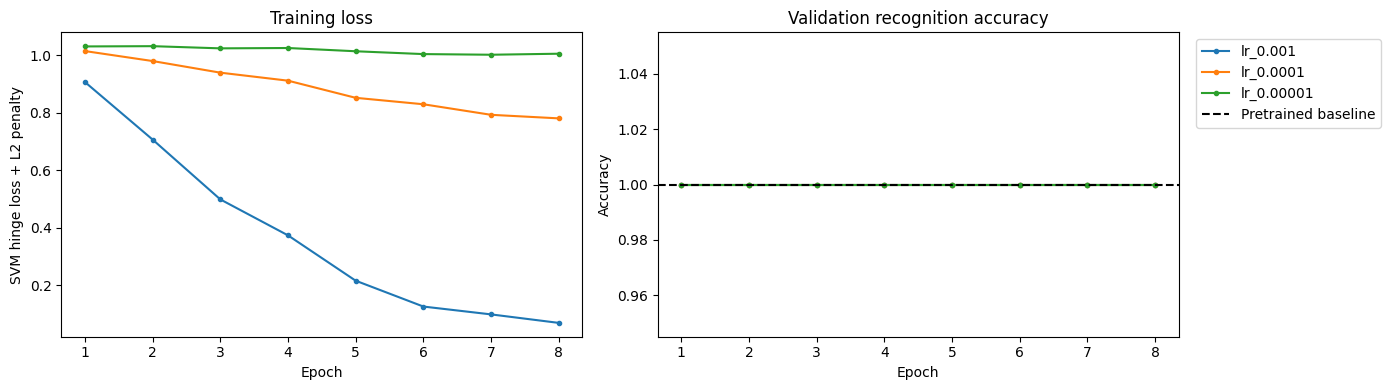

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download contains configurations, epoch logs, comparison, plots, and checkpoints.


In [ ]:
# Plot training loss and validation accuracy.
import matplotlib.pyplot as plt
history_df = pd.DataFrame(all_history)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for name, group in history_df.groupby('experiment', sort=False):
    axes[0].plot(group['epoch'], group['train_loss'], marker='.', label=name)
    axes[1].plot(group['epoch'], group['validation_accuracy'], marker='.', label=name)
axes[0].set(title='Training loss', xlabel='Epoch', ylabel='SVM hinge loss + L2 penalty')
axes[1].set(title='Validation recognition accuracy', xlabel='Epoch', ylabel='Accuracy')
axes[1].axhline(baseline_accuracy, color='black', linestyle='--', label='Pretrained baseline')
axes[1].legend(bbox_to_anchor=(1.02, 1), loc='upper left')
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'training_curves.png', dpi=160, bbox_inches='tight')
plt.show()
# Package the logs, plots and checkpoints for download.
shutil.make_archive('part3_results', 'zip', OUTPUT_DIR)
files.download('part3_results.zip')
print('Download contains configurations, epoch logs, comparison, plots, and checkpoints.')

## Part 4 - Evaluation and Error Analysis

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    ConfusionMatrixDisplay
)

# Create the same architecture and apply Person 3's selected weights.
evaluation_model = MobileFaceNet(embedding_size=512).to(device)
evaluation_model.load_state_dict(best_state)

evaluation_models = {
    'Baseline': baseline,
    'Fine-tuned': evaluation_model
}

gallery_names = train['subject'].to_numpy()

In [ ]:
def get_embeddings(backbone, frame):
    vectors = []
    backbone.eval()

    with torch.no_grad():
        for images, _ in make_loader(
            frame, test_transform, shuffle=False
        ):
            embeddings = backbone(images.to(device))
            vectors.append(embeddings.cpu().numpy())

    return np.concatenate(vectors, axis=0)


def predict_embeddings(query_vectors, gallery_vectors, threshold=None):
    predictions = []
    scores = []

    for vector in query_vectors:
        matches = search_gallery(
            vector.reshape(1, -1),
            gallery_vectors,
            gallery_names,
            threshold=threshold
        )

        predicted, similarity = matches[0]
        predictions.append(predicted)
        scores.append(float(similarity))

    return np.array(predictions), np.array(scores)

Baseline | Fixed threshold: 0.90 | Validation accuracy: 1.0000
Fine-tuned | Fixed threshold: 0.90 | Validation accuracy: 1.0000


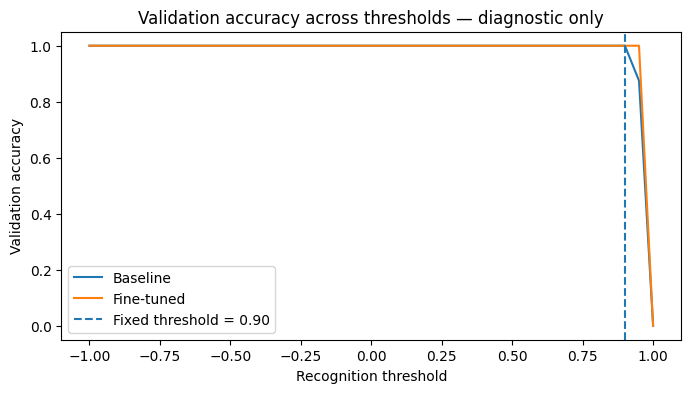

In [ ]:
# Use the same fixed recognition threshold for both models.
FIXED_THRESHOLD = 0.90

# These values are used only for the diagnostic plot.
threshold_values = np.linspace(-1, 1, 41)

galleries = {}
selected_thresholds = {
    name: FIXED_THRESHOLD
    for name in evaluation_models
}

actual = validation['subject'].to_numpy()

plt.figure(figsize=(8, 4))

for name, backbone in evaluation_models.items():
    # Build each model's gallery once, using training images only.
    galleries[name] = get_embeddings(backbone, train)
    validation_vectors = get_embeddings(backbone, validation)

    # Obtain closest matches and scores without rejecting any matches yet.
    candidates, similarities = predict_embeddings(
        validation_vectors,
        galleries[name],
        threshold=None
    )

    # Explore thresholds for visualization only.
    # Do NOT change selected_thresholds here.
    validation_accuracies = []

    for threshold in threshold_values:
        predicted = np.where(
            similarities >= threshold,
            candidates,
            'Unknown'
        )

        validation_accuracies.append(
            accuracy_score(actual, predicted)
        )

    plt.plot(
        threshold_values,
        validation_accuracies,
        label=name
    )

    # Report validation accuracy at the fixed threshold.
    fixed_predictions = np.where(
        similarities >= selected_thresholds[name],
        candidates,
        'Unknown'
    )

    fixed_accuracy = accuracy_score(actual, fixed_predictions)

    print(
        f"{name} | Fixed threshold: {selected_thresholds[name]:.2f}"
        f" | Validation accuracy: {fixed_accuracy:.4f}"
    )

# Mark the cutoff actually used for evaluation.
plt.axvline(
    FIXED_THRESHOLD,
    linestyle='--',
    label=f'Fixed threshold = {FIXED_THRESHOLD:.2f}'
)

plt.xlabel('Recognition threshold')
plt.ylabel('Validation accuracy')
plt.title('Validation accuracy across thresholds — diagnostic only')
plt.legend()
plt.show()

In [ ]:
evaluation_results = {}
comparison_rows = []

actual = test['subject'].to_numpy()

for name, backbone in evaluation_models.items():
    test_vectors = get_embeddings(backbone, test)

    predicted, similarities = predict_embeddings(
        test_vectors,
        galleries[name],
        threshold=selected_thresholds[name]
    )

    evaluation_results[name] = pd.DataFrame({
        'path': test['path'].to_numpy(),
        'actual': actual,
        'predicted': predicted,
        'similarity': similarities
    })

    comparison_rows.append({
        'Model': name,
        'Accuracy': accuracy_score(actual, predicted),
        'Precision': precision_score(
            actual, predicted,
            labels=class_names,
            average='macro',
            zero_division=0
        ),
        'Recall': recall_score(
            actual, predicted,
            labels=class_names,
            average='macro',
            zero_division=0
        ),
        'F1': f1_score(
            actual, predicted,
            labels=class_names,
            average='macro',
            zero_division=0
        ),
        'Not recognized': int(np.sum(predicted == 'Unknown'))
    })

comparison = pd.DataFrame(comparison_rows)
display(comparison.round(4))

,Model,Accuracy,Precision,Recall,F1,Not recognized
0,Baseline,1.0,1.0,1.0,1.0,0
1,Fine-tuned,1.0,1.0,1.0,1.0,0


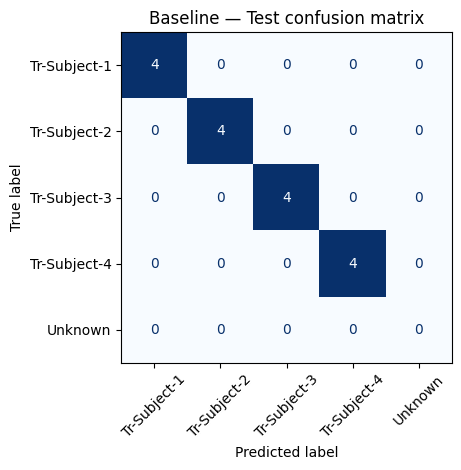

Baseline : 0 errors out of 16


,path,actual,predicted,similarity


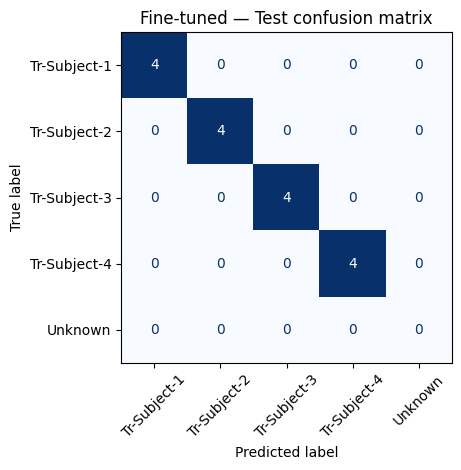

Fine-tuned : 0 errors out of 16


,path,actual,predicted,similarity


Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.


In [ ]:
for name, result in evaluation_results.items():
    ConfusionMatrixDisplay.from_predictions(
        result['actual'],
        result['predicted'],
        labels=class_names + ['Unknown'],
        cmap='Blues',
        colorbar=False,
        xticks_rotation=45
    )

    plt.title(name + ' — Test confusion matrix')
    plt.tight_layout()
    plt.show()

    errors = result[
        result['actual'] != result['predicted']
    ]

    print(name, ':', len(errors), 'errors out of', len(result))
    display(errors)

    if len(errors) > 0:
        plt.figure(figsize=(12, 3))

        for i, (_, row) in enumerate(errors.head(4).iterrows()):
            plt.subplot(1, 4, i + 1)

            with Image.open(row['path']) as image:
                plt.imshow(image.convert('RGB'))

            plt.title(
                f"Actual: {row['actual']}\n"
                f"Predicted: {row['predicted']}\n"
                f"Similarity: {row['similarity']:.2f}",
                fontsize=9
            )
            plt.axis('off')

        plt.tight_layout()
        plt.show()